# UK confectionery sales: cleaning a messy dataset, then finding where the profit is

**Brief:** a confectionery council wants to improve regional distribution and gross profit. Which products have the largest and smallest margins in each region, when do regions peak, and how do regions compare?

**Data:** 1,001 sales records (2000–2005) across five UK regions and six products, with units sold, cost, profit and revenue.

Most of the work here is **cleaning**: the raw file has misspelt products, mislabelled rows, missing values and a broken revenue column. Each fix is checked against the data before it is applied.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import style
from common.style import BLUE, ORANGE, AQUA, MUTED, SERIES

style.apply()
raw = pd.read_excel("data/confectionery_sales.xlsx")
raw.columns = ["date", "region", "product", "units", "cost", "profit", "revenue"]
print(raw.shape)
raw.head()

(1001, 7)


,date,region,product,units,cost,profit,revenue
0,2002-11-11,England,Biscuit,1118.0,2459.6,3130.4,749954.4
1,2002-07-05,England,Biscuit,708.0,1557.6,1982.4,300758.4
2,2001-10-31,England,Biscuit,1269.0,2791.8,3553.2,966216.6
3,2004-09-13,England,Biscuit,1631.0,3588.2,4566.8,1596096.6
4,2004-03-10,England,Biscuit,2240.0,4928.0,6272.0,3010560.0


## 1. Data quality problems

In [2]:
print("Missing values:", raw.isna().sum()[lambda s: s > 0].to_dict())
print("Negative revenue rows:", (raw["revenue"] < 0).sum(), "| zero revenue rows:", (raw["revenue"] == 0).sum())
raw["product"].value_counts()

Missing values: {'units': 5, 'cost': 9, 'profit': 3}
Negative revenue rows: 3 | zero revenue rows: 5


product
Caramel            345
Choclate Chunk     130
Biscuit Nut        125
Biscuit            124
Plain              112
Caramel nut         82
Caramel Nut         67
Chocolate Chunk     16
Name: count, dtype: int64

**Problem 1: inconsistent spelling.** "Choclate Chunk" / "Chocolate Chunk" and "Caramel nut" / "Caramel Nut" are the same products.

In [3]:
df = raw.copy()
df["product"] = (df["product"].str.strip().str.replace("Choclate", "Chocolate", regex=False)
                 .str.replace("Caramel nut", "Caramel Nut", regex=False))
df["product"].value_counts()

product
Caramel            345
Caramel Nut        149
Chocolate Chunk    146
Biscuit Nut        125
Biscuit            124
Plain              112
Name: count, dtype: int64

**Problem 2: mislabelled products.** Every product has a fixed cost and profit per unit, except "Caramel", which shows five different unit costs:

In [4]:
df["unit_cost"] = (df["cost"] / df["units"]).round(2)
df["unit_profit"] = (df["profit"] / df["units"]).round(2)
pd.crosstab(df["product"], df["unit_cost"])

unit_cost,0.20,1.25,1.50,2.00,2.20,2.75
product,,,,,,
Biscuit,0,0,0,0,123,0
Biscuit Nut,0,0,121,0,0,0
Caramel,14,16,15,270,14,15
Caramel Nut,0,0,0,0,0,147
Chocolate Chunk,0,143,0,0,0,0
Plain,109,0,0,0,0,0


The odd "Caramel" unit costs (£0.20, £1.25, £1.50, £2.20, £2.75) are exactly the unit costs of the *other* products, and they occur only in **England**. These are other products recorded as "Caramel". Since each unit cost belongs to exactly one product, the true product can be recovered:

In [5]:
price_book = (df[df["product"] != "Caramel"].dropna(subset=["unit_cost"])
              .groupby("product")[["unit_cost", "unit_profit"]].agg(lambda s: s.mode()[0]))
price_book.loc["Caramel"] = [2.00, 3.00]
by_cost = {round(c, 2): p for p, c in price_book["unit_cost"].items()}

wrong = (df["product"] == "Caramel") & df["unit_cost"].notna() & (df["unit_cost"] != 2.00)
print(f"{wrong.sum()} rows relabelled, all in: {df.loc[wrong, 'region'].unique().tolist()}")
df.loc[wrong, "product"] = df.loc[wrong, "unit_cost"].map(by_cost)
price_book

74 rows relabelled, all in: ['England']


,unit_cost,unit_profit
product,,
Biscuit,2.20,2.80
Biscuit Nut,1.50,2.50
Caramel Nut,2.75,3.25
Chocolate Chunk,1.25,1.75
Plain,0.20,0.80
Caramel,2.00,3.00


**Problem 3: missing values.** With fixed unit prices, a missing cost, profit or units value can be rebuilt from the other columns.

In [6]:
missing_before = df[["units", "cost", "profit"]].isna().sum().sum()
uc = df["product"].map(price_book["unit_cost"])
up = df["product"].map(price_book["unit_profit"])
df["units"] = df["units"].fillna((df["cost"] / uc).round()).fillna((df["profit"] / up).round())
df["cost"] = df["cost"].fillna(df["units"] * uc)
df["profit"] = df["profit"].fillna(df["units"] * up)
print(f"Filled {missing_before} missing values; remaining: {df[['units', 'cost', 'profit']].isna().sum().sum()}")

Filled 17 missing values; remaining: 0


**Problem 4: the revenue column uses the wrong formula.** It equals units × (profit − cost), which is why some values are negative or zero:

In [7]:
formula = df["units"] * (df["profit"] - df["cost"])
match = np.isclose(formula, raw["revenue"], rtol=1e-6)
print(f"revenue == units × (profit − cost) for {match.mean():.0%} of rows")
df["sales"] = df["cost"] + df["profit"]      # true sales value
df["margin"] = df["profit"] / df["sales"]
df = df.drop(columns=["revenue", "unit_cost", "unit_profit"])
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df.head()

revenue == units × (profit − cost) for 98% of rows

,date,region,product,units,cost,profit,sales,margin,year,month
0,2002-11-11,England,Biscuit,1118.0,2459.6,3130.4,5590.0,0.56,2002,11
1,2002-07-05,England,Biscuit,708.0,1557.6,1982.4,3540.0,0.56,2002,7
2,2001-10-31,England,Biscuit,1269.0,2791.8,3553.2,6345.0,0.56,2001,10
3,2004-09-13,England,Biscuit,1631.0,3588.2,4566.8,8155.0,0.56,2004,9
4,2004-03-10,England,Biscuit,2240.0,4928.0,6272.0,11200.0,0.56,2004,3


## 2. Which products are most profitable?

In [8]:
products = df.groupby("product").agg(units=("units", "sum"), sales=("sales", "sum"), profit=("profit", "sum"))
products["margin_%"] = 100 * products["profit"] / products["sales"]
products["profit_per_unit"] = price_book["unit_profit"]
products = products.sort_values("profit", ascending=False)
products.round(1)

,units,sales,profit,margin_%,profit_per_unit
product,,,,,
Caramel,454583.0,2272915.0,1363749.0,60.0,3.0
Caramel Nut,245910.0,1475460.0,799207.5,54.2,3.2
Biscuit,238012.0,1190060.0,666433.6,56.0,2.8
Biscuit Nut,230890.0,923560.0,577225.0,62.5,2.5
Chocolate Chunk,254406.0,763218.0,445210.5,58.3,1.8
Plain,210442.0,210442.0,168353.6,80.0,0.8


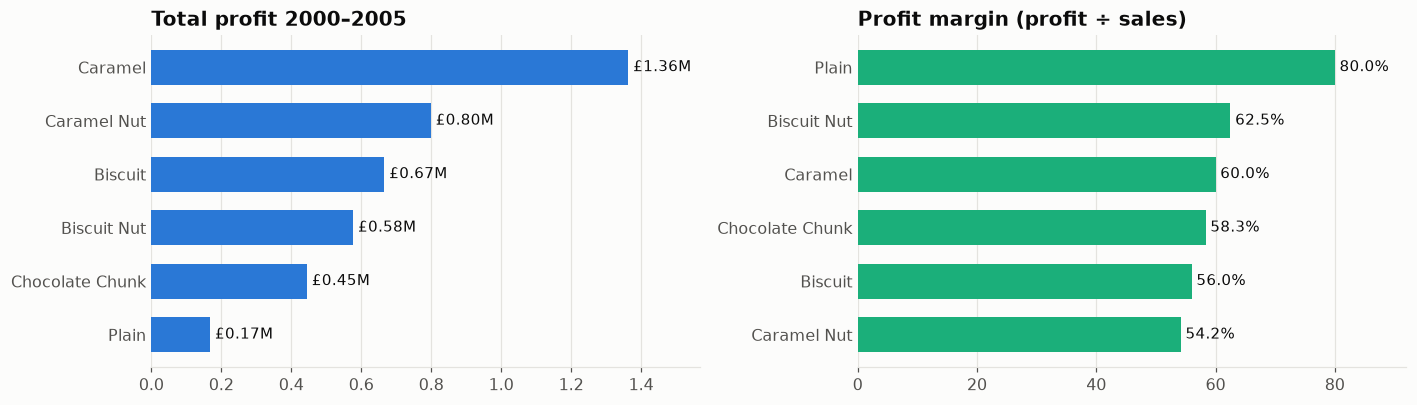

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
style.hbar(axes[0], products.index, products["profit"] / 1e6, fmt="£{:.2f}M")
axes[0].set_title("Total profit 2000–2005")
m = products.sort_values("margin_%", ascending=False)
style.hbar(axes[1], m.index, m["margin_%"], fmt="{:.1f}%", color=AQUA)
axes[1].set_title("Profit margin (profit ÷ sales)")
fig.tight_layout()
style.save(fig, "product_profit_margin")
plt.show()

Because prices are fixed, each product's margin is the same in every region. The brief's question "largest and smallest margin per region" therefore has the same answer everywhere, so the more useful view is where each product **earns** its profit:

In [10]:
region_product = df.pivot_table(index="region", columns="product", values="profit", aggfunc="sum").fillna(0)
share = region_product.div(region_product.sum(axis=1), axis=0).mul(100).round(1)
share

product,Biscuit,Biscuit Nut,Caramel,Caramel Nut,Chocolate Chunk,Plain
region,,,,,,
England,15.4,17.8,24.8,23.6,15.4,2.9
Jersey,16.9,12.0,37.6,18.2,11.2,4.1
N. Ireland,16.6,12.7,38.4,17.6,9.4,5.3
Scotland,16.3,15.0,35.7,19.6,9.2,4.2
Wales,17.6,14.9,31.1,21.1,10.9,4.3


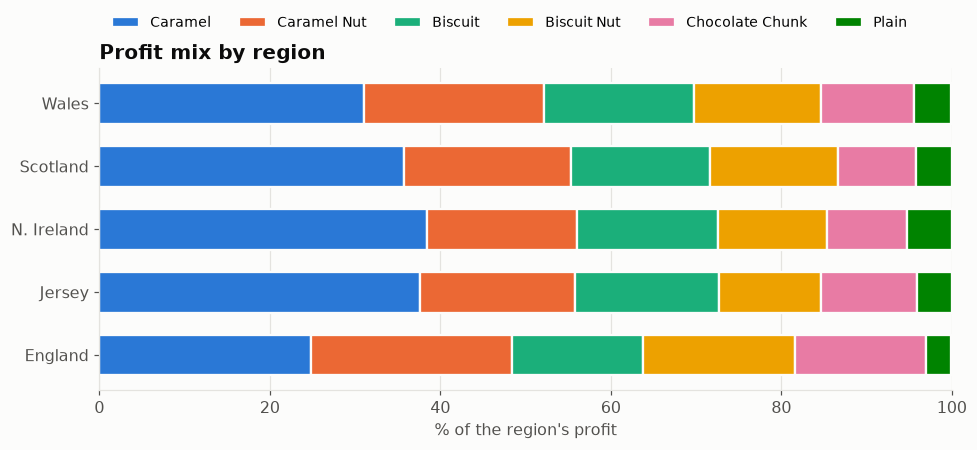

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(share))
order = products.index.tolist()
for prod, color in zip(order, SERIES):
    ax.barh(share.index, share[prod], left=left, color=color, label=prod, height=0.65, edgecolor="#fcfcfb", linewidth=1.5)
    left += share[prod].values
ax.set_xlim(0, 100)
ax.set_xlabel("% of the region's profit")
ax.set_title("Profit mix by region")
ax.legend(loc="lower left", ncols=6, bbox_to_anchor=(0, 1.08), fontsize=9)
ax.grid(axis="y", visible=False)
style.save(fig, "region_profit_mix")
plt.show()

## 3. How do regions compare, and when do they peak?

In [12]:
regions = df.groupby("region").agg(records=("date", "size"), units=("units", "sum"), profit=("profit", "sum"))
regions["profit_per_record"] = regions["profit"] / regions["records"]
regions.sort_values("profit", ascending=False).round(0)

,records,units,profit,profit_per_record
region,,,,
Scotland,210,379222.0,942055.0,4486.0
Jersey,210,370304.0,913679.0,4351.0
N. Ireland,210,308040.0,746995.0,3557.0
Wales,210,294446.0,723060.0,3443.0
England,161,282231.0,694391.0,4313.0


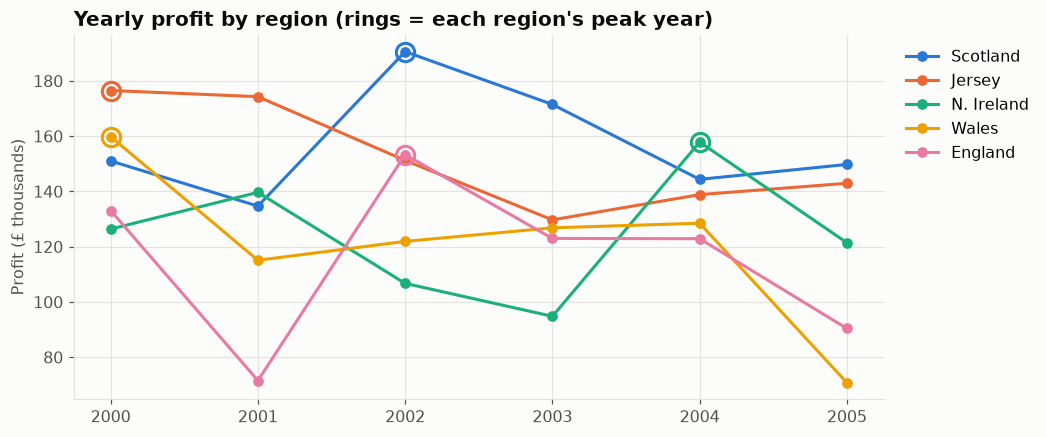

,peak_year,peak_profit_k,lowest_year
region,,,
England,2002,153.0,2001
Jersey,2000,177.0,2003
N. Ireland,2004,158.0,2003
Scotland,2002,191.0,2001
Wales,2000,160.0,2005


In [13]:
yearly = df.pivot_table(index="year", columns="region", values="profit", aggfunc="sum") / 1e3
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for reg, color in zip(regions.sort_values("profit", ascending=False).index, SERIES):
    ax.plot(yearly.index, yearly[reg], "-o", color=color, lw=2, label=reg)
    peak = yearly[reg].idxmax()
    ax.plot(peak, yearly.loc[peak, reg], "o", ms=12, mfc="none", mec=color, mew=2)
ax.set_ylabel("Profit (£ thousands)")
ax.set_title("Yearly profit by region (rings = each region's peak year)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
style.save(fig, "yearly_profit_by_region")
plt.show()
peaks = pd.DataFrame({"peak_year": yearly.idxmax(), "peak_profit_k": yearly.max().round(0),
                      "lowest_year": yearly.idxmin()})
peaks

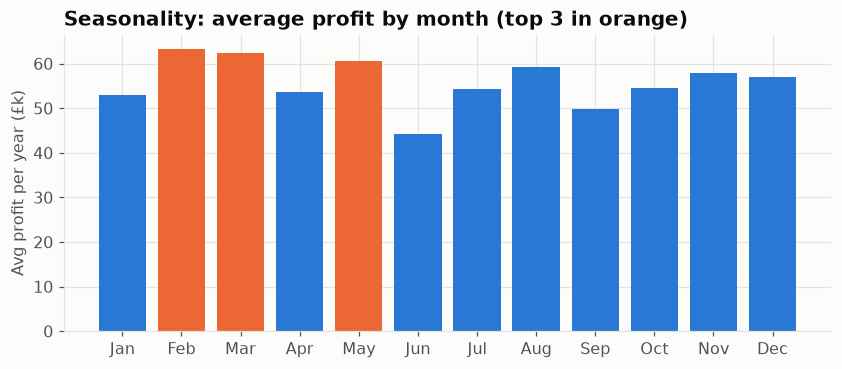

In [14]:
monthly = df.groupby("month")["profit"].sum() / df["year"].nunique() / 1e3
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.index, monthly.values, color=[ORANGE if m in monthly.nlargest(3).index else BLUE for m in monthly.index])
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Avg profit per year (£k)")
ax.set_title("Seasonality: average profit by month (top 3 in orange)")
style.save(fig, "seasonality")
plt.show()

## Key findings and recommendations

In [15]:
top, low_margin = products.index[0], products["margin_%"].idxmin()
best_region = regions["profit"].idxmax()
eng = regions.loc["England"]
print(f"1. Data quality: {wrong.sum()} England rows were mislabelled as Caramel, {missing_before} values were missing "
      f"and the revenue column used a wrong formula; all were corrected before analysis.")
print(f"2. {top} earns the most profit (£{products.loc[top, 'profit'] / 1e6:.2f}M) thanks to volume and a high "
      f"£{products.loc[top, 'profit_per_unit']:.2f} profit per unit.")
print(f"3. Plain has the best margin ({products.loc['Plain', 'margin_%']:.0f}%) but earns only "
      f"£{products.loc['Plain', 'profit_per_unit']:.2f} per unit; {low_margin} has the lowest margin "
      f"({products.loc[low_margin, 'margin_%']:.0f}%) but the highest profit per unit (£{products.loc[low_margin, 'profit_per_unit']:.2f}). "
      "Margin alone is the wrong target.")
rank = regions["profit_per_record"].rank(ascending=False).astype(int)
print(f"4. {best_region} is the most profitable region (£{regions.loc[best_region, 'profit'] / 1e6:.2f}M). England ranks last on "
      f"total profit only because it has fewer records ({eng['records']:.0f} vs 210 elsewhere): its profit per sale "
      f"(£{eng['profit_per_record']:,.0f}) ranks #{rank['England']} of 5.")
print(f"5. Peak years differ by region ({', '.join(f'{r} {y}' for r, y in peaks['peak_year'].items())}), and the best "
      f"months overall are {', '.join(pd.to_datetime(monthly.nlargest(3).index, format='%m').strftime('%B'))}.")
print("Recommendations: prioritise distribution of Caramel and Caramel Nut, which drive profit per unit; investigate why "
      "England has 23% fewer records than every other region (missing data or a real distribution gap); "
      "fix the revenue formula and product coding at the source.")

1. Data quality: 74 England rows were mislabelled as Caramel, 17 values were missing and the revenue column used a wrong formula; all were corrected before analysis.
2. Caramel earns the most profit (£1.36M) thanks to volume and a high £3.00 profit per unit.
3. Plain has the best margin (80%) but earns only £0.80 per unit; Caramel Nut has the lowest margin (54%) but the highest profit per unit (£3.25). Margin alone is the wrong target.
4. Scotland is the most profitable region (£0.94M). England ranks last on total profit only because it has fewer records (161 vs 210 elsewhere): its profit per sale (£4,313) ranks #3 of 5.
5. Peak years differ by region (England 2002, Jersey 2000, N. Ireland 2004, Scotland 2002, Wales 2000), and the best months overall are February, March, May.
Recommendations: prioritise distribution of Caramel and Caramel Nut, which drive profit per unit; investigate why England has 23% fewer records than every other region (missing data or a real distribution gap); fi